In [24]:
# Deep Learning Lab — Program 1
## Optimization, Regularization and Architecture Experiments on Fashion-MNIST (PyTorch)

In [25]:

import time
import copy
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, Dataset

import torchvision
from torchvision import datasets, transforms

# ---- Automatic GPU / CPU detection ----
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---- Reproducibility ----
SEED = 42

def set_seed(seed=SEED):
    """Fix all random number generators so results are repeatable."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

# Nicer default plot style
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True

print(f"PyTorch version     : {torch.__version__}")
print(f"Torchvision version : {torchvision.__version__}")
print(f"Device in use       : {device}")
if device.type == "cuda":
    print(f"GPU name            : {torch.cuda.get_device_name(0)}")

PyTorch version     : 2.14.1+cpu
Torchvision version : 0.29.1+cpu
Device in use       : cpu


In [26]:

# Download Fashion-MNIST using torchvision
train_full = datasets.FashionMNIST(root="./data", train=True,  download=True)
test_full  = datasets.FashionMNIST(root="./data", train=False, download=True)

CLASS_NAMES = train_full.classes          # 10 class names
NUM_CLASSES = len(CLASS_NAMES)
INPUT_DIM   = 28 * 28                     # 784 features after flattening

# Subset sizes (kept small so every experiment trains quickly)
N_TRAIN = 10000
N_VAL   = 2000
N_TEST  = 2000

# Raw pixels are uint8 in [0, 255] -> divide by 255 to normalize to [0, 1]
# (this is exactly what transforms.ToTensor() does, but done on the whole tensor at once)
X_all = train_full.data.float() / 255.0   # shape: (60000, 28, 28)
y_all = train_full.targets                # shape: (60000,)

X_test_all = test_full.data.float() / 255.0
y_test_all = test_full.targets

# Fixed-seed random shuffling so the split is identical every run
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(X_all), generator=g)
train_idx = perm[:N_TRAIN]
val_idx   = perm[N_TRAIN:N_TRAIN + N_VAL]
test_idx  = torch.randperm(len(X_test_all), generator=g)[:N_TEST]

# Flatten each 28x28 image into a 784-length vector
X_train = X_all[train_idx].view(-1, INPUT_DIM)
y_train = y_all[train_idx]

X_val = X_all[val_idx].view(-1, INPUT_DIM)
y_val = y_all[val_idx]

X_test = X_test_all[test_idx].view(-1, INPUT_DIM)
y_test = y_test_all[test_idx]

# Wrap the tensors as PyTorch datasets
train_ds = TensorDataset(X_train, y_train)
val_ds   = TensorDataset(X_val,   y_val)
test_ds  = TensorDataset(X_test,  y_test)

print("Train :", X_train.shape, y_train.shape)
print("Val   :", X_val.shape,   y_val.shape)
print("Test  :", X_test.shape,  y_test.shape)
print(f"Pixel range after normalization: [{X_train.min():.1f}, {X_train.max():.1f}]")

Train : torch.Size([10000, 784]) torch.Size([10000])
Val   : torch.Size([2000, 784]) torch.Size([2000])
Test  : torch.Size([2000, 784]) torch.Size([2000])
Pixel range after normalization: [0.0, 1.0]


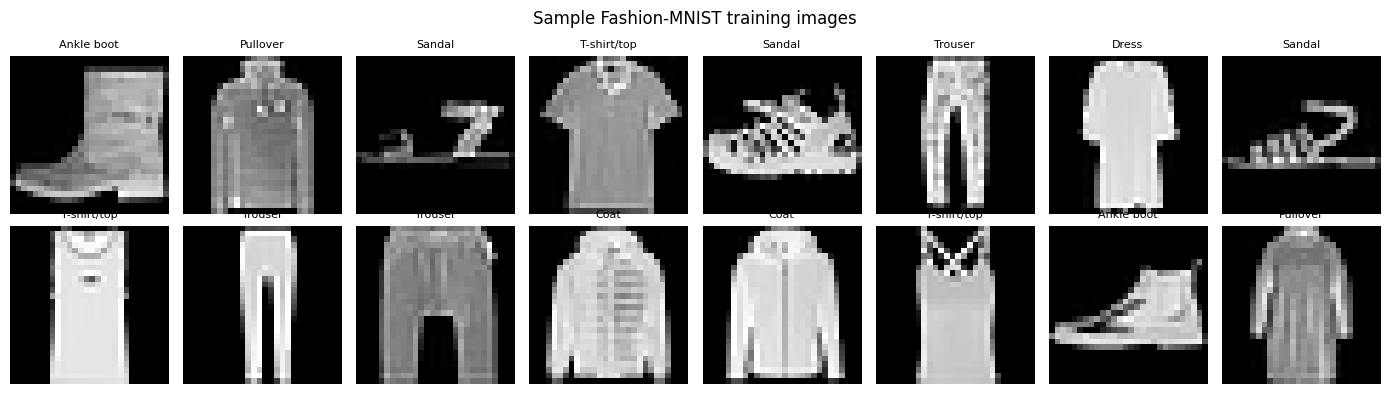

,Class,Train,Val,Test
0,T-shirt/top,980,179,174
1,Trouser,979,185,226
2,Pullover,1061,192,187
3,Dress,974,198,195
4,Coat,1046,194,199
5,Sandal,1055,206,205
6,Shirt,984,211,199
7,Sneaker,993,219,205
8,Bag,957,194,201
9,Ankle boot,971,222,209


One mini-batch -> torch.Size([64, 784]) torch.Size([64])


In [27]:

def make_loader(dataset, batch_size, shuffle=False):
    """Create a DataLoader whose shuffling order is reproducible."""
    gen = torch.Generator().manual_seed(SEED)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, generator=gen)

# ---- Show a few training images (reshape 784 -> 28x28 just for display) ----
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i].view(28, 28), cmap="gray")
    ax.set_title(CLASS_NAMES[y_train[i]], fontsize=8)
    ax.axis("off")
plt.suptitle("Sample Fashion-MNIST training images")
plt.tight_layout()
plt.show()

# ---- Class distribution in each split (checks the subset is balanced) ----
class_dist = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Train": torch.bincount(y_train, minlength=NUM_CLASSES).numpy(),
    "Val":   torch.bincount(y_val,   minlength=NUM_CLASSES).numpy(),
    "Test":  torch.bincount(y_test,  minlength=NUM_CLASSES).numpy(),
})
display(class_dist)

# ---- Sanity check: one mini-batch from the loader ----
xb, yb = next(iter(make_loader(train_ds, batch_size=64, shuffle=True)))
print("One mini-batch ->", xb.shape, yb.shape)

In [28]:

class MLP(nn.Module):
    """
    Plain fully-connected network.
    hidden_dims : sizes of hidden layers, e.g. (256, 128)
    dropout     : dropout probability after each hidden layer (0 = no dropout)
    """
    def __init__(self, input_dim=INPUT_DIM, hidden_dims=(256, 128),
                 num_classes=NUM_CLASSES, dropout=0.0):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.append(nn.Linear(prev, h))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, num_classes))   # output layer (raw scores / logits)
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def count_params(model):
    """Number of trainable parameters in a model."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Quick check of the architecture
set_seed(SEED)
demo_model = MLP()
print(demo_model)
print("Trainable parameters:", count_params(demo_model))

MLP(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 235146


In [29]:

criterion = nn.CrossEntropyLoss()

def train_one_epoch(model, loader, optimizer):
    """One pass over the training data. Returns (avg loss, accuracy)."""
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()            # 1. clear old gradients
        outputs = model(xb)              # 2. forward pass
        loss = criterion(outputs, yb)    # 3. compute loss
        loss.backward()                  # 4. backpropagation
        optimizer.step()                 # 5. update weights
        total_loss += loss.item() * xb.size(0)
        correct += (outputs.argmax(dim=1) == yb).sum().item()
        n += xb.size(0)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, loader):
    """Evaluate without updating weights. Returns (avg loss, accuracy)."""
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        outputs = model(xb)
        total_loss += criterion(outputs, yb).item() * xb.size(0)
        correct += (outputs.argmax(dim=1) == yb).sum().item()
        n += xb.size(0)
    return total_loss / n, correct / n


def train_model(model, optimizer, train_loader, val_loader, epochs,
                scheduler=None, verbose=True):
    """Full training loop. Returns a history dictionary."""
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}
    start = time.time()
    for epoch in range(1, epochs + 1):
        history["lr"].append(optimizer.param_groups[0]["lr"])   # LR used in this epoch
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer)
        va_loss, va_acc = evaluate(model, val_loader)
        if scheduler is not None:
            scheduler.step()                                    # update LR once per epoch
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)
        if verbose:
            print(f"Epoch {epoch:3d}/{epochs} | "
                  f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
                  f"val loss {va_loss:.4f} acc {va_acc:.4f}")
    history["time"] = time.time() - start
    return history


# Fixed evaluation loaders (no shuffling needed for validation / test)
val_loader  = make_loader(val_ds,  batch_size=512)
test_loader = make_loader(test_ds, batch_size=512)


def plot_compare(histories, metric, title, ylabel):
    """Plot one metric (e.g. 'val_acc') for several runs on the same axes."""
    plt.figure()
    for name, h in histories.items():
        plt.plot(range(1, len(h[metric]) + 1), h[metric], marker="o", markersize=3, label=name)
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.legend()
    plt.show()


def plot_train_val(history, title):
    """Training vs validation loss and accuracy for a single run."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
    ax1.plot(epochs, history["train_loss"], label="Train loss")
    ax1.plot(epochs, history["val_loss"],   label="Val loss")
    ax1.set_title(f"{title} — Loss"); ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.legend()
    ax2.plot(epochs, history["train_acc"], label="Train acc")
    ax2.plot(epochs, history["val_acc"],   label="Val acc")
    ax2.set_title(f"{title} — Accuracy"); ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy"); ax2.legend()
    plt.tight_layout()
    plt.show()

print("Training utilities ready.")

Training utilities ready.


In [30]:

GD_LR = 0.05          # same learning rate for all three -> only batch size differs

gd_configs = {
    "Batch GD":           len(train_ds),   # whole training set per update
    "Stochastic GD":      1,               # one sample per update
    "Mini-batch GD (64)": 64,              # 64 samples per update
}

gd_histories = {}
for name, bs in gd_configs.items():
    print(f"\n=== {name} (batch size = {bs}) ===")
    set_seed(SEED)
    model = MLP().to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=GD_LR)   # plain GD update rule
    train_loader = make_loader(train_ds, batch_size=bs, shuffle=True)
    gd_histories[name] = train_model(model, optimizer, train_loader, val_loader, GD_EPOCHS)
    print(f"Time taken: {gd_histories[name]['time']:.2f} s")


=== Batch GD (batch size = 10000) ===
Epoch   1/5 | train loss 2.3045 acc 0.1124 | val loss 2.2994 acc 0.1245
Epoch   2/5 | train loss 2.3003 acc 0.1191 | val loss 2.2954 acc 0.1355
Epoch   3/5 | train loss 2.2961 acc 0.1328 | val loss 2.2915 acc 0.1590
Epoch   4/5 | train loss 2.2921 acc 0.1564 | val loss 2.2876 acc 0.1820
Epoch   5/5 | train loss 2.2880 acc 0.1779 | val loss 2.2837 acc 0.2055
Time taken: 1.96 s

=== Stochastic GD (batch size = 1) ===
Epoch   1/5 | train loss 1.0695 acc 0.6058 | val loss 1.1779 acc 0.5475
Epoch   2/5 | train loss 1.0383 acc 0.6347 | val loss 4.8919 acc 0.4685
Epoch   3/5 | train loss 1.0873 acc 0.6370 | val loss 2.1575 acc 0.3575
Epoch   4/5 | train loss 1.2381 acc 0.5641 | val loss 1.1516 acc 0.5210
Epoch   5/5 | train loss 1.7164 acc 0.4902 | val loss 1.0058 acc 0.6115
Time taken: 65.12 s

=== Mini-batch GD (64) (batch size = 64) ===
Epoch   1/5 | train loss 1.5549 acc 0.4813 | val loss 1.0492 acc 0.6360
Epoch   2/5 | train loss 0.8358 acc 0.6810 |

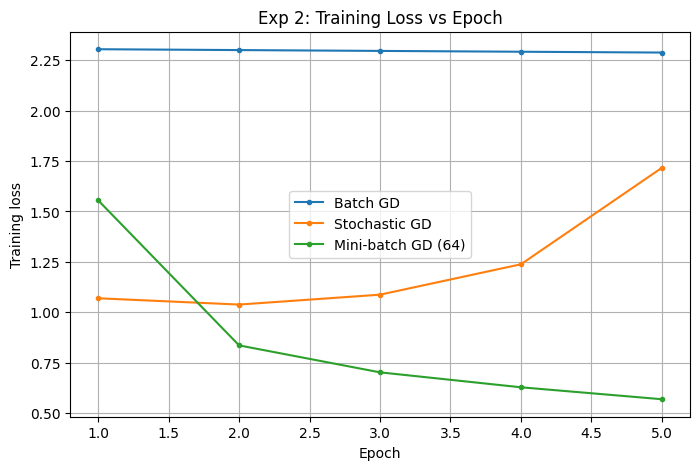

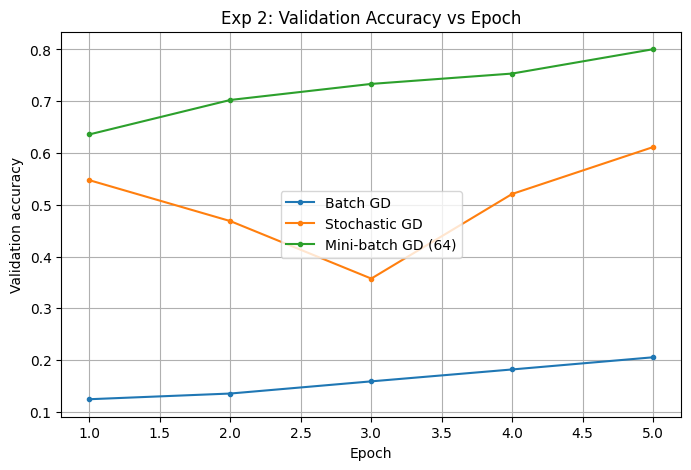

,Method,Batch size,Updates per epoch,Final train loss,Final val acc,Best val acc,Time (s)
0,Batch GD,10000,1,2.2880,0.2055,0.2055,1.96
1,Stochastic GD,1,10000,1.7164,0.6115,0.6115,65.12
2,Mini-batch GD (64),64,157,0.5689,0.8005,0.8005,2.94


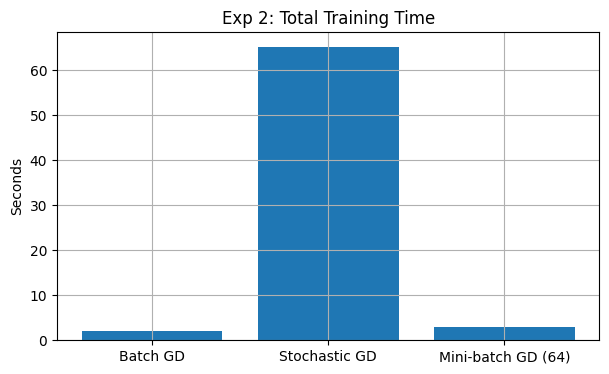

In [31]:

plot_compare(gd_histories, "train_loss", "Exp 2: Training Loss vs Epoch", "Training loss")
plot_compare(gd_histories, "val_acc",    "Exp 2: Validation Accuracy vs Epoch", "Validation accuracy")

gd_rows = []
for name, bs in gd_configs.items():
    h = gd_histories[name]
    gd_rows.append({
        "Method": name,
        "Batch size": bs,
        "Updates per epoch": int(np.ceil(len(train_ds) / bs)),
        "Final train loss": round(h["train_loss"][-1], 4),
        "Final val acc": round(h["val_acc"][-1], 4),
        "Best val acc": round(max(h["val_acc"]), 4),
        "Time (s)": round(h["time"], 2),
    })
gd_table = pd.DataFrame(gd_rows)
display(gd_table)

plt.figure(figsize=(7, 4))
plt.bar(gd_table["Method"], gd_table["Time (s)"])
plt.title("Exp 2: Total Training Time")
plt.ylabel("Seconds")
plt.show()

In [32]:

BATCH_SIZE = 64
OPT_EPOCHS = 10

opt_configs = {
    "SGD + Momentum": lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9),
    "Nesterov":       lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9, nesterov=True),
    "RMSprop":        lambda p: torch.optim.RMSprop(p, lr=0.001),
    "Adam":           lambda p: torch.optim.Adam(p, lr=0.001),
    "Adagrad":        lambda p: torch.optim.Adagrad(p, lr=0.01),
}

opt_histories = {}
opt_rows = []
for name, make_optimizer in opt_configs.items():
    print(f"\n=== {name} ===")
    set_seed(SEED)
    model = MLP().to(device)
    optimizer = make_optimizer(model.parameters())
    train_loader = make_loader(train_ds, BATCH_SIZE, shuffle=True)
    h = train_model(model, optimizer, train_loader, val_loader, OPT_EPOCHS)
    _, test_acc = evaluate(model, test_loader)
    opt_histories[name] = h
    opt_rows.append({
        "Optimizer": name,
        "Final train loss": round(h["train_loss"][-1], 4),
        "Final val loss": round(h["val_loss"][-1], 4),
        "Best val acc": round(max(h["val_acc"]), 4),
        "Test acc": round(test_acc, 4),
        "Time (s)": round(h["time"], 2),
    })

opt_table = pd.DataFrame(opt_rows)


=== SGD + Momentum ===
Epoch   1/10 | train loss 1.3614 acc 0.5160 | val loss 0.7718 acc 0.7000
Epoch   2/10 | train loss 0.6925 acc 0.7453 | val loss 0.6058 acc 0.7700
Epoch   3/10 | train loss 0.5877 acc 0.7915 | val loss 0.5804 acc 0.7830
Epoch   4/10 | train loss 0.5316 acc 0.8121 | val loss 0.4999 acc 0.8190
Epoch   5/10 | train loss 0.4823 acc 0.8308 | val loss 0.4810 acc 0.8250
Epoch   6/10 | train loss 0.4519 acc 0.8386 | val loss 0.4717 acc 0.8295
Epoch   7/10 | train loss 0.4261 acc 0.8452 | val loss 0.4434 acc 0.8380
Epoch   8/10 | train loss 0.4056 acc 0.8546 | val loss 0.4392 acc 0.8360
Epoch   9/10 | train loss 0.3927 acc 0.8563 | val loss 0.4613 acc 0.8365
Epoch  10/10 | train loss 0.3766 acc 0.8640 | val loss 0.4174 acc 0.8465

=== Nesterov ===
Epoch   1/10 | train loss 1.3286 acc 0.5302 | val loss 0.7609 acc 0.7080
Epoch   2/10 | train loss 0.6659 acc 0.7575 | val loss 0.5861 acc 0.7910
Epoch   3/10 | train loss 0.5516 acc 0.8064 | val loss 0.5509 acc 0.7970
Epoch   4

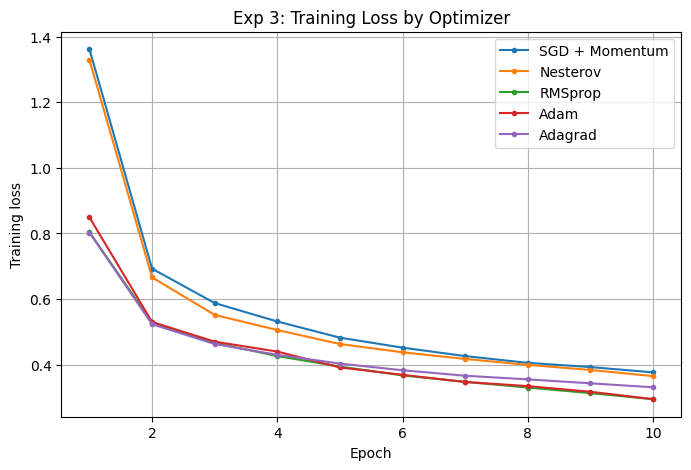

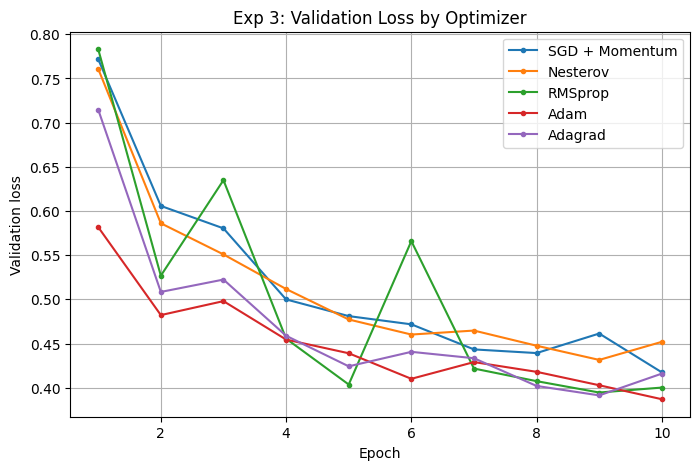

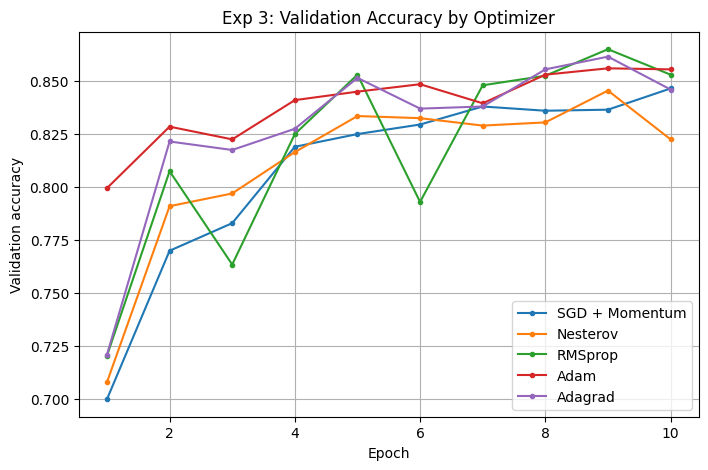

,Optimizer,Final train loss,Final val loss,Best val acc,Test acc,Time (s)
0,SGD + Momentum,0.3766,0.4174,0.8465,0.8360,6.09
1,Nesterov,0.3650,0.4519,0.8455,0.8100,7.45
2,RMSprop,0.2947,0.4002,0.8650,0.8395,8.37
3,Adam,0.2950,0.3870,0.8560,0.8575,9.76
4,Adagrad,0.3310,0.4160,0.8615,0.8370,9.55


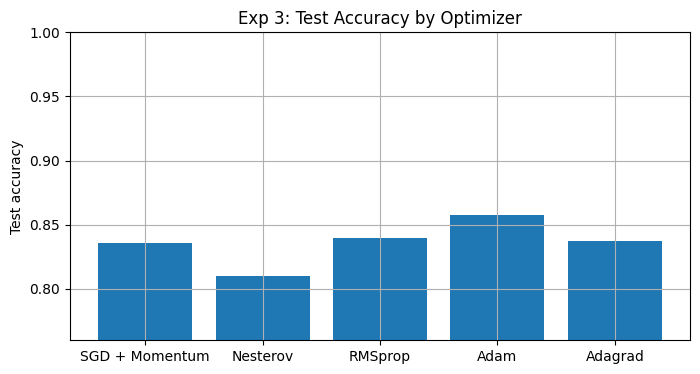

In [33]:

plot_compare(opt_histories, "train_loss", "Exp 3: Training Loss by Optimizer", "Training loss")
plot_compare(opt_histories, "val_loss",   "Exp 3: Validation Loss by Optimizer", "Validation loss")
plot_compare(opt_histories, "val_acc",    "Exp 3: Validation Accuracy by Optimizer", "Validation accuracy")

display(opt_table)

plt.figure(figsize=(8, 4))
plt.bar(opt_table["Optimizer"], opt_table["Test acc"])
plt.ylim(opt_table["Test acc"].min() - 0.05, 1.0)
plt.title("Exp 3: Test Accuracy by Optimizer")
plt.ylabel("Test accuracy")
plt.show()

In [34]:

LR_EPOCHS = 15
BASE_LR = 0.05

def make_scheduler(name, optimizer):
    if name == "Constant LR":
        return None
    if name == "StepLR":
        return torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)
    if name == "ExponentialLR":
        return torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.85)
    raise ValueError(f"Unknown scheduler: {name}")

lr_histories = {}
lr_rows = []
for name in ["Constant LR", "StepLR", "ExponentialLR"]:
    print(f"\n=== {name} ===")
    set_seed(SEED)
    model = MLP().to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=BASE_LR, momentum=0.9)
    scheduler = make_scheduler(name, optimizer)
    train_loader = make_loader(train_ds, BATCH_SIZE, shuffle=True)
    h = train_model(model, optimizer, train_loader, val_loader, LR_EPOCHS, scheduler=scheduler)
    _, test_acc = evaluate(model, test_loader)
    lr_histories[name] = h
    lr_rows.append({
        "Schedule": name,
        "Initial LR": h["lr"][0],
        "Final LR": round(h["lr"][-1], 6),
        "Final train loss": round(h["train_loss"][-1], 4),
        "Final val loss": round(h["val_loss"][-1], 4),
        "Best val acc": round(max(h["val_acc"]), 4),
        "Test acc": round(test_acc, 4),
    })

lr_table = pd.DataFrame(lr_rows)


=== Constant LR ===
Epoch   1/15 | train loss 0.9299 acc 0.6580 | val loss 0.5348 acc 0.8090
Epoch   2/15 | train loss 0.5496 acc 0.8019 | val loss 0.4881 acc 0.8065
Epoch   3/15 | train loss 0.4891 acc 0.8225 | val loss 0.5324 acc 0.8105
Epoch   4/15 | train loss 0.4759 acc 0.8222 | val loss 0.4295 acc 0.8410
Epoch   5/15 | train loss 0.4188 acc 0.8410 | val loss 0.4658 acc 0.8310
Epoch   6/15 | train loss 0.3861 acc 0.8545 | val loss 0.4404 acc 0.8350
Epoch   7/15 | train loss 0.3864 acc 0.8549 | val loss 0.3945 acc 0.8585
Epoch   8/15 | train loss 0.3647 acc 0.8620 | val loss 0.4163 acc 0.8465
Epoch   9/15 | train loss 0.3445 acc 0.8708 | val loss 0.3976 acc 0.8565
Epoch  10/15 | train loss 0.3404 acc 0.8739 | val loss 0.4077 acc 0.8495
Epoch  11/15 | train loss 0.3258 acc 0.8740 | val loss 0.3726 acc 0.8705
Epoch  12/15 | train loss 0.3054 acc 0.8812 | val loss 0.3640 acc 0.8710
Epoch  13/15 | train loss 0.2865 acc 0.8907 | val loss 0.3521 acc 0.8680
Epoch  14/15 | train loss 0.27

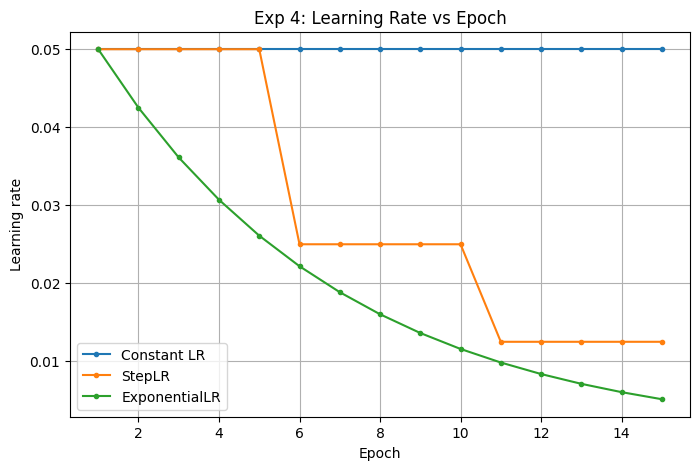

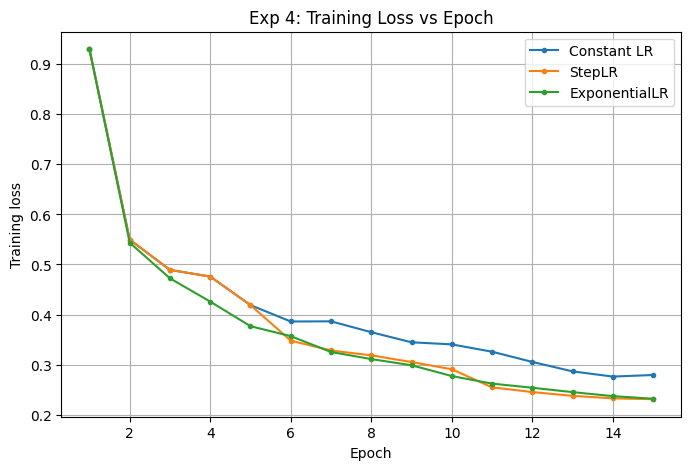

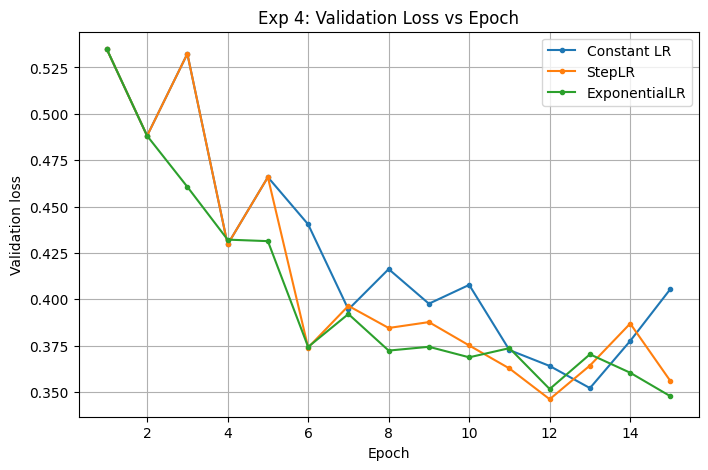

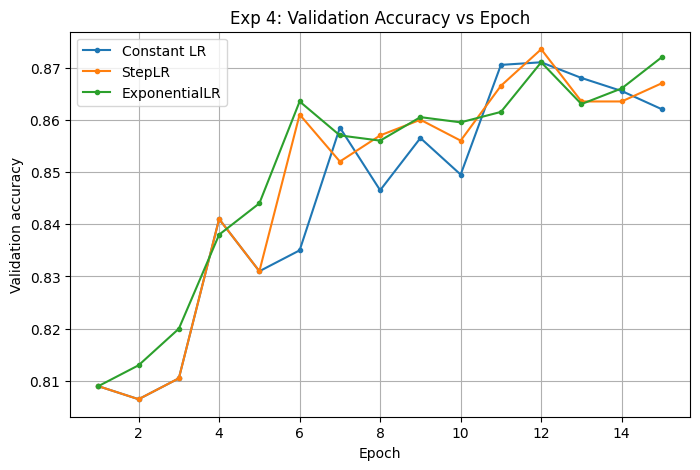

,Schedule,Initial LR,Final LR,Final train loss,Final val loss,Best val acc,Test acc
0,Constant LR,0.05,0.050000,0.2792,0.4056,0.8710,0.851
1,StepLR,0.05,0.012500,0.2309,0.3558,0.8735,0.867
2,ExponentialLR,0.05,0.005138,0.2318,0.3476,0.8720,0.871


In [35]:
# ============================================================
# Cell 16: EXPERIMENT 4 — Learning-rate and loss plots + table
# ============================================================
plot_compare(lr_histories, "lr",         "Exp 4: Learning Rate vs Epoch", "Learning rate")
plot_compare(lr_histories, "train_loss", "Exp 4: Training Loss vs Epoch", "Training loss")
plot_compare(lr_histories, "val_loss",   "Exp 4: Validation Loss vs Epoch", "Validation loss")
plot_compare(lr_histories, "val_acc",    "Exp 4: Validation Accuracy vs Epoch", "Validation accuracy")

display(lr_table)

Parameters: 669706
Epoch   1/40 | train loss 1.6037 acc 0.4610 | val loss 0.9404 acc 0.6485
Epoch   2/40 | train loss 0.8745 acc 0.6490 | val loss 0.7644 acc 0.7140
Epoch   3/40 | train loss 0.7217 acc 0.7370 | val loss 0.7013 acc 0.7355
Epoch   4/40 | train loss 0.6127 acc 0.7800 | val loss 0.6465 acc 0.7625
Epoch   5/40 | train loss 0.5071 acc 0.8130 | val loss 0.6438 acc 0.7840
Epoch   6/40 | train loss 0.5098 acc 0.8070 | val loss 0.6578 acc 0.7575
Epoch   7/40 | train loss 0.4468 acc 0.8250 | val loss 0.6397 acc 0.7680
Epoch   8/40 | train loss 0.4265 acc 0.8520 | val loss 0.5855 acc 0.8080
Epoch   9/40 | train loss 0.3618 acc 0.8790 | val loss 0.5932 acc 0.8050
Epoch  10/40 | train loss 0.3030 acc 0.9110 | val loss 0.5846 acc 0.8050
Epoch  11/40 | train loss 0.3367 acc 0.8800 | val loss 0.7165 acc 0.7835
Epoch  12/40 | train loss 0.3409 acc 0.8940 | val loss 0.6621 acc 0.8120
Epoch  13/40 | train loss 0.2541 acc 0.9230 | val loss 0.5990 acc 0.8320
Epoch  14/40 | train loss 0.2338

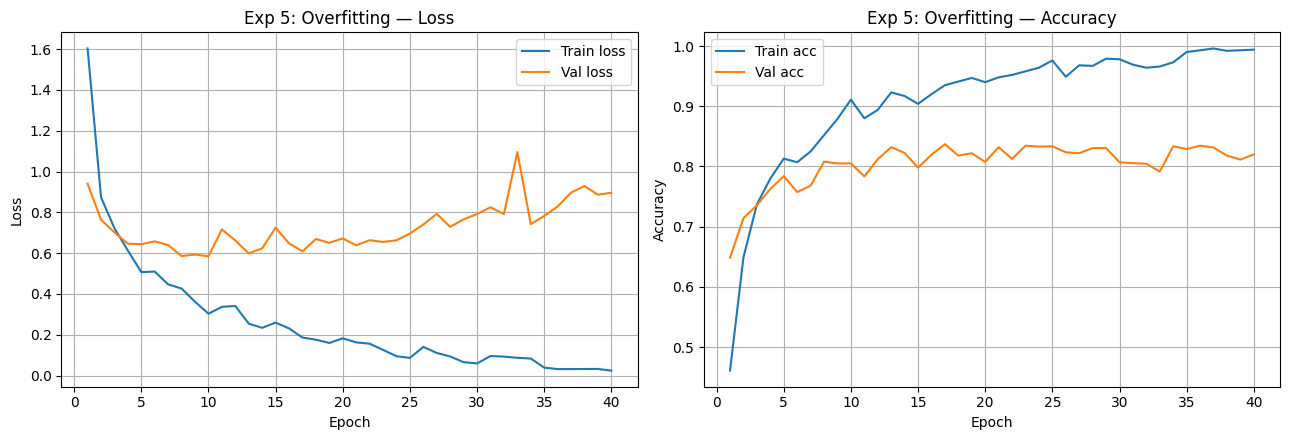

,Training samples,Epochs,Epoch of min val loss,Min val loss,Final val loss,Final train loss,Final train acc,Final val acc,Accuracy gap (train - val)
0,1000,40,10,0.5846,0.8962,0.0241,0.994,0.82,0.174


Validation loss was lowest at epoch 10; epochs after that are where overfitting shows.


In [36]:

OVERFIT_N = 1000
OVERFIT_EPOCHS = 40
BIG_HIDDEN = (512, 512)

overfit_train_ds = TensorDataset(X_train[:OVERFIT_N], y_train[:OVERFIT_N])

set_seed(SEED)
overfit_model = MLP(hidden_dims=BIG_HIDDEN).to(device)
print("Parameters:", count_params(overfit_model))
optimizer = torch.optim.Adam(overfit_model.parameters(), lr=1e-3)
train_loader = make_loader(overfit_train_ds, BATCH_SIZE, shuffle=True)
overfit_history = train_model(overfit_model, optimizer, train_loader, val_loader, OVERFIT_EPOCHS)

plot_train_val(overfit_history, "Exp 5: Overfitting")

best_ep = int(np.argmin(overfit_history["val_loss"])) + 1
overfit_table = pd.DataFrame([{
    "Training samples": OVERFIT_N,
    "Epochs": OVERFIT_EPOCHS,
    "Epoch of min val loss": best_ep,
    "Min val loss": round(min(overfit_history["val_loss"]), 4),
    "Final val loss": round(overfit_history["val_loss"][-1], 4),
    "Final train loss": round(overfit_history["train_loss"][-1], 4),
    "Final train acc": round(overfit_history["train_acc"][-1], 4),
    "Final val acc": round(overfit_history["val_acc"][-1], 4),
    "Accuracy gap (train - val)": round(overfit_history["train_acc"][-1] - overfit_history["val_acc"][-1], 4),
}])
display(overfit_table)
print(f"Validation loss was lowest at epoch {best_ep}; epochs after that are where overfitting shows.")

In [37]:

class AugmentedDataset(Dataset):
    """Applies a random image transform to each flattened sample on the fly."""
    def __init__(self, X, y, transform):
        self.X = X
        self.y = y
        self.transform = transform

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        img = self.X[idx].view(1, 28, 28)        # 784 -> 1x28x28 image
        img = self.transform(img)                # random rotation + translation
        return img.view(-1), self.y[idx]         # back to 784 features


REG_N = 2000
REG_EPOCHS = 30
DROPOUT_P = 0.3
L2_LAMBDA = 1e-3

reg_train_ds = TensorDataset(X_train[:REG_N], y_train[:REG_N])
augment = transforms.RandomAffine(degrees=10, translate=(0.1, 0.1))
aug_train_ds = AugmentedDataset(X_train[:REG_N], y_train[:REG_N], augment)
clean_train_eval_loader = make_loader(reg_train_ds, batch_size=512)

reg_configs = {
    "Baseline":                 {"dropout": 0.0,       "weight_decay": 0.0,       "dataset": reg_train_ds},
    f"Dropout (p={DROPOUT_P})": {"dropout": DROPOUT_P, "weight_decay": 0.0,       "dataset": reg_train_ds},
    f"L2 (lambda={L2_LAMBDA})": {"dropout": 0.0,       "weight_decay": L2_LAMBDA, "dataset": reg_train_ds},
    "Data Augmentation":        {"dropout": 0.0,       "weight_decay": 0.0,       "dataset": aug_train_ds},
}

reg_histories = {}
reg_rows = []
for name, cfg in reg_configs.items():
    print(f"\n=== {name} ===")
    set_seed(SEED)
    model = MLP(hidden_dims=BIG_HIDDEN, dropout=cfg["dropout"]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=cfg["weight_decay"])
    train_loader = make_loader(cfg["dataset"], BATCH_SIZE, shuffle=True)
    h = train_model(model, optimizer, train_loader, val_loader, REG_EPOCHS, verbose=False)
    _, clean_train_acc = evaluate(model, clean_train_eval_loader)
    _, test_acc = evaluate(model, test_loader)
    reg_histories[name] = h
    reg_rows.append({
        "Method": name,
        "Train acc (clean)": round(clean_train_acc, 4),
        "Final val acc": round(h["val_acc"][-1], 4),
        "Gap (train - val)": round(clean_train_acc - h["val_acc"][-1], 4),
        "Min val loss": round(min(h["val_loss"]), 4),
        "Final val loss": round(h["val_loss"][-1], 4),
        "Test acc": round(test_acc, 4),
        "Time (s)": round(h["time"], 2),
    })
    print(f"Final val acc {h['val_acc'][-1]:.4f} | test acc {test_acc:.4f} | time {h['time']:.1f}s")

reg_table = pd.DataFrame(reg_rows)


=== Baseline ===
Final val acc 0.8390 | test acc 0.8365 | time 14.4s

=== Dropout (p=0.3) ===
Final val acc 0.8490 | test acc 0.8395 | time 16.8s

=== L2 (lambda=0.001) ===
Final val acc 0.8345 | test acc 0.8295 | time 14.5s

=== Data Augmentation ===
Final val acc 0.8040 | test acc 0.8035 | time 50.0s


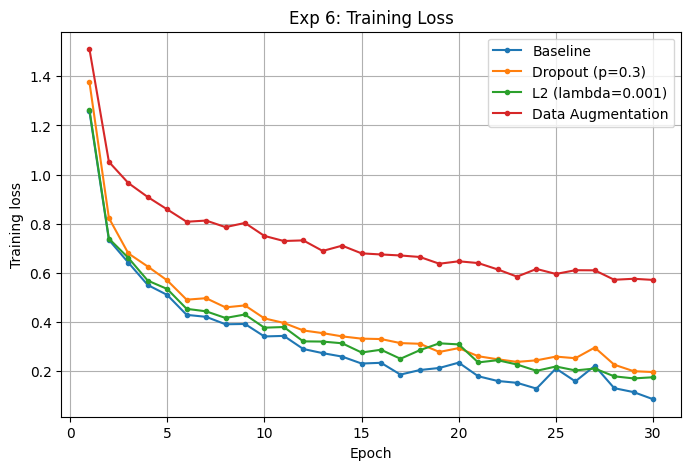

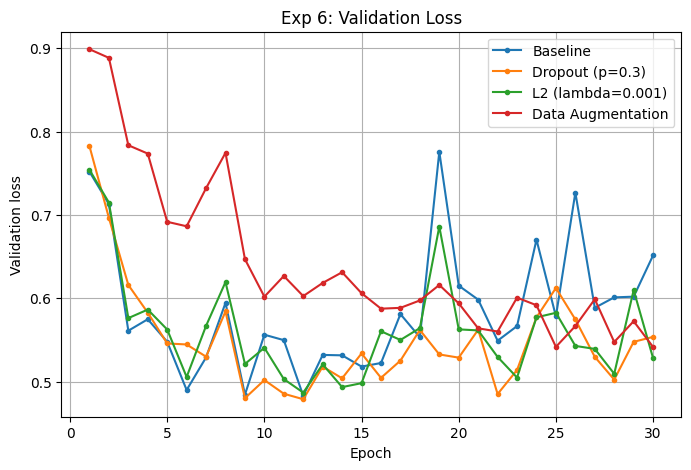

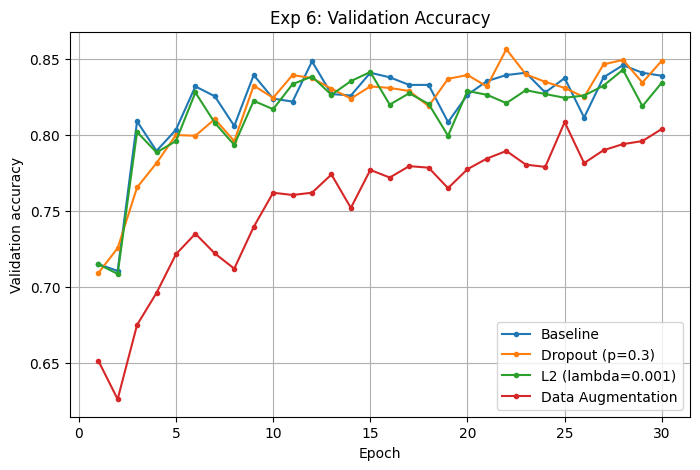

Regularization comparison table:


,Method,Train acc (clean),Final val acc,Gap (train - val),Min val loss,Final val loss,Test acc,Time (s)
0,Baseline,0.9815,0.8390,0.1425,0.4830,0.6515,0.8365,14.40
1,Dropout (p=0.3),0.9575,0.8490,0.1085,0.4789,0.5537,0.8395,16.77
2,L2 (lambda=0.001),0.9660,0.8345,0.1315,0.4868,0.5281,0.8295,14.53
3,Data Augmentation,0.8210,0.8040,0.0170,0.5415,0.5415,0.8035,50.00


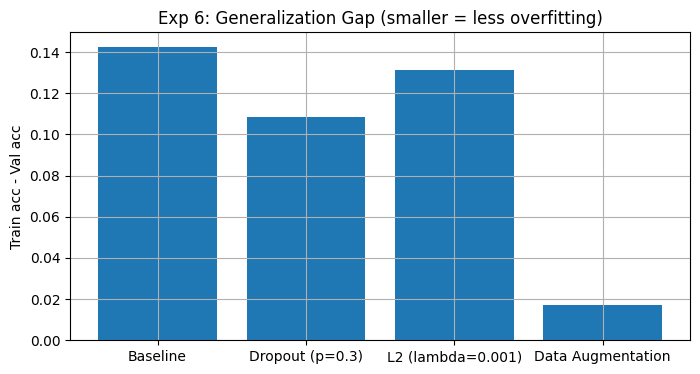

In [38]:
# ============================================================
# Cell 21: EXPERIMENT 6 — Regularization plots + comparison table
# ============================================================
plot_compare(reg_histories, "train_loss", "Exp 6: Training Loss", "Training loss")
plot_compare(reg_histories, "val_loss",   "Exp 6: Validation Loss", "Validation loss")
plot_compare(reg_histories, "val_acc",    "Exp 6: Validation Accuracy", "Validation accuracy")

print("Regularization comparison table:")
display(reg_table)

plt.figure(figsize=(8, 4))
plt.bar(reg_table["Method"], reg_table["Gap (train - val)"])
plt.title("Exp 6: Generalization Gap (smaller = less overfitting)")
plt.ylabel("Train acc - Val acc")
plt.show()

In [39]:

def train_with_early_stopping(model, optimizer, train_loader, val_loader,
                              max_epochs=60, patience=5, min_delta=0.0,
                              save_path="best_model.pt", verbose=True):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0
    start = time.time()

    for epoch in range(1, max_epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer)
        va_loss, va_acc = evaluate(model, val_loader)
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)

        if va_loss < best_val_loss - min_delta:          # improvement
            best_val_loss = va_loss
            best_epoch = epoch
            epochs_without_improvement = 0
            torch.save(model.state_dict(), save_path)    # save best weights
            note = "<- best, saved"
        else:                                            # no improvement
            epochs_without_improvement += 1
            note = f"(no improvement {epochs_without_improvement}/{patience})"

        if verbose:
            print(f"Epoch {epoch:3d} | train loss {tr_loss:.4f} | val loss {va_loss:.4f} "
                  f"| val acc {va_acc:.4f} {note}")

        if epochs_without_improvement >= patience:
            print(f"Early stopping triggered at epoch {epoch}.")
            break

    history["time"] = time.time() - start
    history["stopped_epoch"] = epoch
    history["best_epoch"] = best_epoch
    history["best_val_loss"] = best_val_loss

    # Restore the best weights
    model.load_state_dict(torch.load(save_path, map_location=device))
    print(f"Restored weights from best epoch {best_epoch} (val loss {best_val_loss:.4f}).")
    return history


ES_MAX_EPOCHS = 60
PATIENCE = 5                         # main configurable patience
PATIENCE_VALUES = [3, PATIENCE, 10]  # extra runs to compare patience settings

es_histories = {}
es_rows = []
for p in PATIENCE_VALUES:
    print(f"\n=== Early stopping with patience = {p} ===")
    set_seed(SEED)
    model = MLP(hidden_dims=BIG_HIDDEN).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    train_loader = make_loader(reg_train_ds, BATCH_SIZE, shuffle=True)
    h = train_with_early_stopping(model, optimizer, train_loader, val_loader,
                                  max_epochs=ES_MAX_EPOCHS, patience=p,
                                  save_path=f"best_model_patience{p}.pt",
                                  verbose=(p == PATIENCE))
    _, test_acc = evaluate(model, test_loader)   # evaluated with restored best weights
    es_histories[p] = h
    es_rows.append({
        "Patience": p,
        "Best epoch": h["best_epoch"],
        "Stopped at epoch": h["stopped_epoch"],
        "Best val loss": round(h["best_val_loss"], 4),
        "Test acc (best weights)": round(test_acc, 4),
        "Time (s)": round(h["time"], 2),
    })

es_table = pd.DataFrame(es_rows)


=== Early stopping with patience = 3 ===
Early stopping triggered at epoch 15.
Restored weights from best epoch 12 (val loss 0.4830).

=== Early stopping with patience = 5 ===
Epoch   1 | train loss 1.2568 | val loss 0.7519 | val acc 0.7150 <- best, saved
Epoch   2 | train loss 0.7337 | val loss 0.7130 | val acc 0.7105 <- best, saved
Epoch   3 | train loss 0.6413 | val loss 0.5611 | val acc 0.8090 <- best, saved
Epoch   4 | train loss 0.5499 | val loss 0.5748 | val acc 0.7895 (no improvement 1/5)
Epoch   5 | train loss 0.5096 | val loss 0.5478 | val acc 0.8035 <- best, saved
Epoch   6 | train loss 0.4284 | val loss 0.4899 | val acc 0.8320 <- best, saved
Epoch   7 | train loss 0.4204 | val loss 0.5290 | val acc 0.8255 (no improvement 1/5)
Epoch   8 | train loss 0.3901 | val loss 0.5945 | val acc 0.8060 (no improvement 2/5)
Epoch   9 | train loss 0.3913 | val loss 0.4843 | val acc 0.8395 <- best, saved
Epoch  10 | train loss 0.3405 | val loss 0.5563 | val acc 0.8240 (no improvement 1/5)

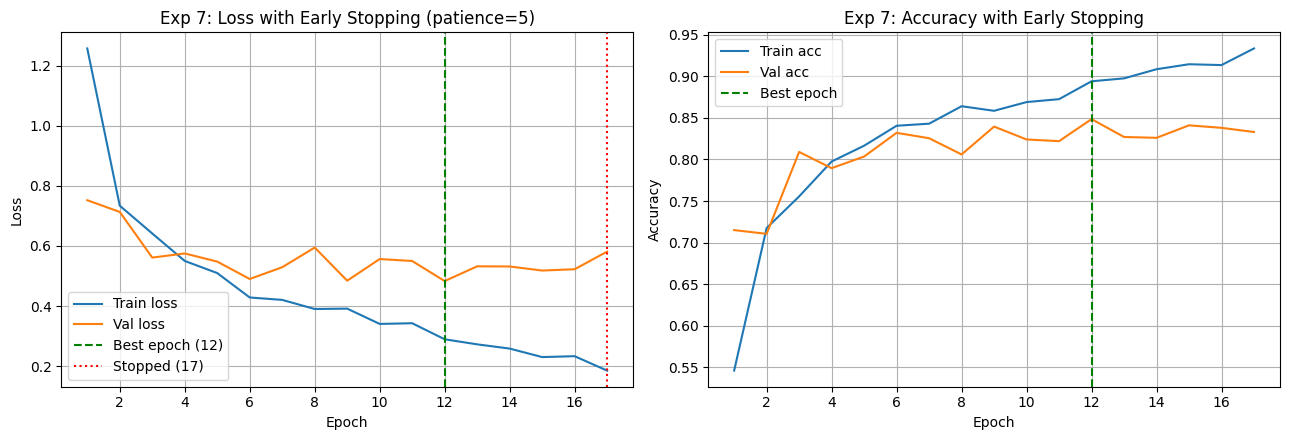

,Patience,Best epoch,Stopped at epoch,Best val loss,Test acc (best weights),Time (s)
0,3,12,15,0.483,0.8375,7.78
1,5,12,17,0.483,0.8375,7.52
2,10,12,22,0.483,0.8375,10.58


Patience 5: best epoch = 12.0, test accuracy with restored best weights = 0.8375
For reference, Exp 6 baseline (same data, fixed 30 epochs) test acc = 0.8365


In [40]:

h = es_histories[PATIENCE]
epochs = range(1, len(h["val_loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(epochs, h["train_loss"], label="Train loss")
ax1.plot(epochs, h["val_loss"],   label="Val loss")
ax1.axvline(h["best_epoch"],    color="green", linestyle="--", label=f"Best epoch ({h['best_epoch']})")
ax1.axvline(h["stopped_epoch"], color="red",   linestyle=":",  label=f"Stopped ({h['stopped_epoch']})")
ax1.set_title(f"Exp 7: Loss with Early Stopping (patience={PATIENCE})")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.legend()

ax2.plot(epochs, h["train_acc"], label="Train acc")
ax2.plot(epochs, h["val_acc"],   label="Val acc")
ax2.axvline(h["best_epoch"], color="green", linestyle="--", label="Best epoch")
ax2.set_title("Exp 7: Accuracy with Early Stopping")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy"); ax2.legend()
plt.tight_layout()
plt.show()

display(es_table)

main = es_table[es_table["Patience"] == PATIENCE].iloc[0]
print(f"Patience {PATIENCE}: best epoch = {main['Best epoch']}, "
      f"test accuracy with restored best weights = {main['Test acc (best weights)']:.4f}")
print(f"For reference, Exp 6 baseline (same data, fixed {REG_EPOCHS} epochs) test acc = "
      f"{reg_table.loc[reg_table['Method'] == 'Baseline', 'Test acc'].iloc[0]:.4f}")

In [41]:

class ResidualBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.fc1 = nn.Linear(dim, dim)
        self.fc2 = nn.Linear(dim, dim)
        self.relu = nn.ReLU()

    def forward(self, x):
        out = self.relu(self.fc1(x))
        out = self.fc2(out)
        return self.relu(out + x)        # skip connection: add the input back


class ResidualMLP(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, hidden_dim=256, num_blocks=3, num_classes=NUM_CLASSES):
        super().__init__()
        self.input_layer = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.ReLU())
        self.blocks = nn.Sequential(*[ResidualBlock(hidden_dim) for _ in range(num_blocks)])
        self.output_layer = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        x = self.input_layer(x)
        x = self.blocks(x)
        return self.output_layer(x)


ARCH_EPOCHS = 15
HIDDEN = 256
NUM_BLOCKS = 3

arch_builders = {
    "Plain MLP":    lambda: MLP(hidden_dims=(HIDDEN,) * (1 + 2 * NUM_BLOCKS)),   # 7 hidden layers
    "Residual MLP": lambda: ResidualMLP(hidden_dim=HIDDEN, num_blocks=NUM_BLOCKS),
}

arch_histories = {}
arch_rows = []
for name, build in arch_builders.items():
    print(f"\n=== {name} ===")
    set_seed(SEED)
    model = build().to(device)
    n_params = count_params(model)
    print("Parameters:", n_params)
    optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
    train_loader = make_loader(train_ds, BATCH_SIZE, shuffle=True)
    h = train_model(model, optimizer, train_loader, val_loader, ARCH_EPOCHS)
    _, test_acc = evaluate(model, test_loader)
    arch_histories[name] = h
    arch_rows.append({
        "Model": name,
        "Parameters": n_params,
        "Final train loss": round(h["train_loss"][-1], 4),
        "Final val loss": round(h["val_loss"][-1], 4),
        "Best val acc": round(max(h["val_acc"]), 4),
        "Test acc": round(test_acc, 4),
        "Training time (s)": round(h["time"], 2),
    })

arch_table = pd.DataFrame(arch_rows)


=== Plain MLP ===
Parameters: 598282
Epoch   1/15 | train loss 2.3029 acc 0.1068 | val loss 2.3025 acc 0.1030
Epoch   2/15 | train loss 2.3023 acc 0.1073 | val loss 2.3037 acc 0.0960
Epoch   3/15 | train loss 2.3011 acc 0.1047 | val loss 2.3012 acc 0.0970
Epoch   4/15 | train loss 2.2935 acc 0.1637 | val loss 2.2702 acc 0.1950
Epoch   5/15 | train loss 1.8848 acc 0.2464 | val loss 1.4928 acc 0.3590
Epoch   6/15 | train loss 1.2092 acc 0.4898 | val loss 1.3162 acc 0.4590
Epoch   7/15 | train loss 0.9965 acc 0.6003 | val loss 0.8915 acc 0.6590
Epoch   8/15 | train loss 0.8822 acc 0.6413 | val loss 0.8037 acc 0.6685
Epoch   9/15 | train loss 0.7753 acc 0.6916 | val loss 0.7808 acc 0.7150
Epoch  10/15 | train loss 0.6935 acc 0.7403 | val loss 0.7383 acc 0.7055
Epoch  11/15 | train loss 0.5974 acc 0.7712 | val loss 0.6257 acc 0.7570
Epoch  12/15 | train loss 0.5673 acc 0.7840 | val loss 0.5533 acc 0.7880
Epoch  13/15 | train loss 0.5427 acc 0.7927 | val loss 0.5150 acc 0.8085
Epoch  14/15 

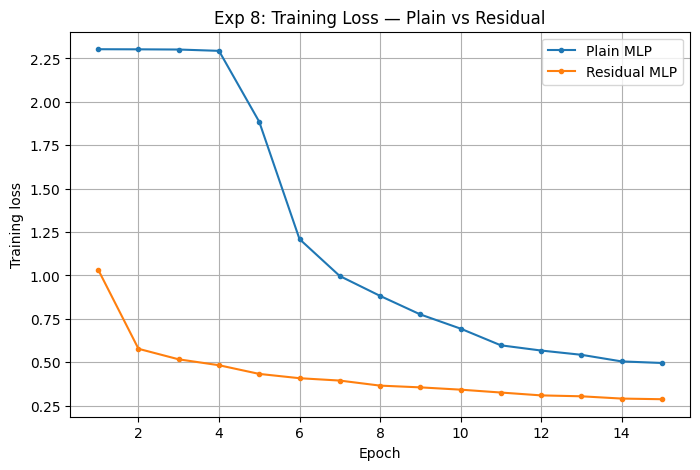

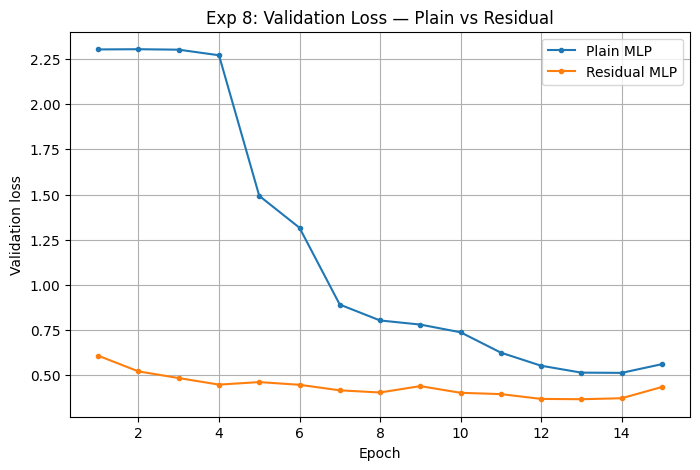

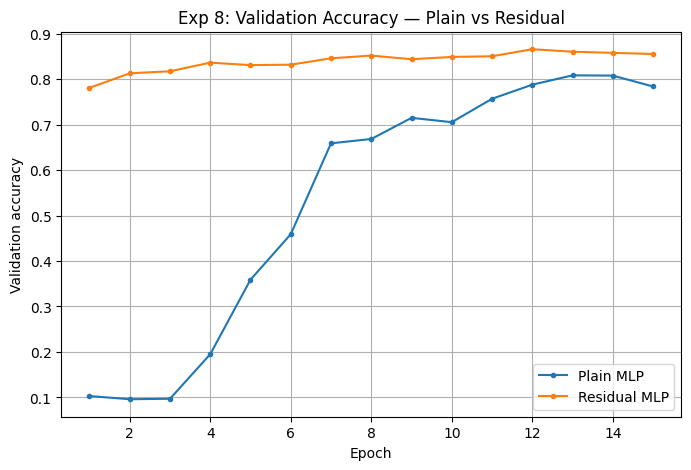

Plain vs Residual MLP comparison table:


,Model,Parameters,Final train loss,Final val loss,Best val acc,Test acc,Training time (s)
0,Plain MLP,598282,0.4956,0.5618,0.8085,0.8035,24.11
1,Residual MLP,598282,0.2868,0.4354,0.8660,0.8430,25.06


In [42]:
# ============================================================
# Cell 27: EXPERIMENT 8 — Plain vs Residual comparison
# ============================================================
plot_compare(arch_histories, "train_loss", "Exp 8: Training Loss — Plain vs Residual", "Training loss")
plot_compare(arch_histories, "val_loss",   "Exp 8: Validation Loss — Plain vs Residual", "Validation loss")
plot_compare(arch_histories, "val_acc",    "Exp 8: Validation Accuracy — Plain vs Residual", "Validation accuracy")

print("Plain vs Residual MLP comparison table:")
display(arch_table)

In [43]:

summary_tables = {
    "Experiment 2 — Gradient Descent Variants": gd_table,
    "Experiment 3 — Optimizer Comparison": opt_table,
    "Experiment 4 — Learning-Rate Scheduling": lr_table,
    "Experiment 5 — Overfitting": overfit_table,
    "Experiment 6 — Regularization Comparison": reg_table,
    "Experiment 7 — Early Stopping": es_table,
    "Experiment 8 — Plain vs Residual MLP": arch_table,
}

for title, table in summary_tables.items():
    print("\n" + "=" * 70)
    print(title)
    print("=" * 70)
    display(table)

# Quick highlights computed from the tables (not hard-coded)
best_opt = opt_table.loc[opt_table["Test acc"].idxmax(), "Optimizer"]
best_sched = lr_table.loc[lr_table["Test acc"].idxmax(), "Schedule"]
best_reg = reg_table.loc[reg_table["Test acc"].idxmax(), "Method"]
best_arch = arch_table.loc[arch_table["Test acc"].idxmax(), "Model"]
fastest_gd = gd_table.loc[gd_table["Time (s)"].idxmin(), "Method"]

print("\nHighlights from this run:")
print(f"  Fastest GD variant           : {fastest_gd}")
print(f"  Best optimizer (test acc)    : {best_opt}")
print(f"  Best LR schedule (test acc)  : {best_sched}")
print(f"  Best regularizer (test acc)  : {best_reg}")
print(f"  Best architecture (test acc) : {best_arch}")
print(f"  Early stopping best epoch    : {es_histories[PATIENCE]['best_epoch']} (patience={PATIENCE})")


Experiment 2 — Gradient Descent Variants


,Method,Batch size,Updates per epoch,Final train loss,Final val acc,Best val acc,Time (s)
0,Batch GD,10000,1,2.2880,0.2055,0.2055,1.96
1,Stochastic GD,1,10000,1.7164,0.6115,0.6115,65.12
2,Mini-batch GD (64),64,157,0.5689,0.8005,0.8005,2.94



Experiment 3 — Optimizer Comparison


,Optimizer,Final train loss,Final val loss,Best val acc,Test acc,Time (s)
0,SGD + Momentum,0.3766,0.4174,0.8465,0.8360,6.09
1,Nesterov,0.3650,0.4519,0.8455,0.8100,7.45
2,RMSprop,0.2947,0.4002,0.8650,0.8395,8.37
3,Adam,0.2950,0.3870,0.8560,0.8575,9.76
4,Adagrad,0.3310,0.4160,0.8615,0.8370,9.55



Experiment 4 — Learning-Rate Scheduling


,Schedule,Initial LR,Final LR,Final train loss,Final val loss,Best val acc,Test acc
0,Constant LR,0.05,0.050000,0.2792,0.4056,0.8710,0.851
1,StepLR,0.05,0.012500,0.2309,0.3558,0.8735,0.867
2,ExponentialLR,0.05,0.005138,0.2318,0.3476,0.8720,0.871


... (5 outputs left out)

,Patience,Best epoch,Stopped at epoch,Best val loss,Test acc (best weights),Time (s)
0,3,12,15,0.483,0.8375,7.78
1,5,12,17,0.483,0.8375,7.52
2,10,12,22,0.483,0.8375,10.58



Experiment 8 — Plain vs Residual MLP


,Model,Parameters,Final train loss,Final val loss,Best val acc,Test acc,Training time (s)
0,Plain MLP,598282,0.4956,0.5618,0.8085,0.8035,24.11
1,Residual MLP,598282,0.2868,0.4354,0.8660,0.8430,25.06



Highlights from this run:
  Fastest GD variant           : Batch GD
  Best optimizer (test acc)    : Adam
  Best LR schedule (test acc)  : ExponentialLR
  Best regularizer (test acc)  : Dropout (p=0.3)
  Best architecture (test acc) : Residual MLP
  Early stopping best epoch    : 12 (patience=5)
